# ステップ1-1 演習: 1変数データ

この Notebook は、本文 [ステップ1-1 記述統計: 1変数データ](../docs/step1-1_univariate.md) の演習です。本文の手計算の例を Python で検算し、続いて工学の例題として、2台のセンサの繰り返し測定のばらつきを比べます。

上のセルから順に実行してください。乱数のシードを固定しているので、誰が実行しても同じ模擬データと同じ結果になります。

## 1. 準備

使うパッケージを読み込み、乱数の生成器を作ります。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 乱数の生成器。シードを固定し、誰が実行しても同じ模擬データになるようにする
rng = np.random.default_rng(seed=20261017)

## 2. 本文の手計算を検算する

### 2-1. 6個の測定値の代表値と散らばり

本文の4節・6節で手計算した、部品の長さの6個の測定値（単位 mm）です。`ddof=1` は、分散を $n-1$ で割る指定です。

In [2]:
x = np.array([10.1, 9.9, 10.0, 10.2, 9.8, 10.6])

mean = x.mean()
var = x.var(ddof=1)
sd = x.std(ddof=1)

print(f"平均       {mean:.3f}")
print(f"中央値     {np.median(x):.3f}")
print(f"範囲       {x.max() - x.min():.3f}")
print(f"分散       {var:.4f}")
print(f"標準偏差   {sd:.4f}")
print(f"変動係数   {sd / mean * 100:.2f} %")
print(f"10.6 のz得点 {(10.6 - mean) / sd:.2f}")

平均       10.100
中央値     10.050
範囲       0.800
分散       0.0800
標準偏差   0.2828
変動係数   2.80 %
10.6 のz得点 1.77


### 2-2. 四分位数の求め方の違い

本文の5節では、データを下半分と上半分に分け、それぞれの中央値を第1四分位数・第3四分位数としました。NumPy の `np.percentile` の既定は、順位の間を直線で補う別の求め方なので、値が少し変わります。

In [3]:
def quartiles_by_halves(data):
    """下半分と上半分の中央値を第1・第3四分位数とする（個数が奇数なら中央の値は両方から除く）"""
    s = np.sort(data)
    n = len(s)
    return np.median(s[: n // 2]), np.median(s[(n + 1) // 2 :])


q1, q3 = quartiles_by_halves(x)
iqr = q3 - q1
print(f"半分に分ける方法      Q1={q1:.3f}  Q3={q3:.3f}  四分位範囲={iqr:.3f}")
p25, p75 = np.percentile(x, [25, 75])
print(f"np.percentile の既定  Q1={p25:.3f}  Q3={p75:.3f}  四分位範囲={p75 - p25:.3f}")
print(f"はずれ値の目安の範囲  {q1 - 1.5 * iqr:.3f} 〜 {q3 + 1.5 * iqr:.3f}")

半分に分ける方法      Q1=9.900  Q3=10.200  四分位範囲=0.300
np.percentile の既定  Q1=9.925  Q3=10.175  四分位範囲=0.250
はずれ値の目安の範囲  9.450 〜 10.650


### 2-3. 度数分布表からの平均

本文の3節の度数分布表（10個の測定値を3つの階級にまとめたもの）から、階級値を使って平均を求めます。

In [4]:
class_marks = np.array([9.8, 10.0, 10.2])
counts = np.array([2, 5, 3])

print(f"相対度数     {counts / counts.sum()}")
print(f"累積相対度数 {np.cumsum(counts) / counts.sum()}")
print(f"平均         {(class_marks * counts).sum() / counts.sum():.3f}")

相対度数     [0.2 0.5 0.3]
累積相対度数 [0.2 0.7 1. ]
平均         10.020


### 2-4. 歪度

本文の7節の式（標準偏差に $n$ で割ったものを使う）で、6個の測定値の歪度を求めます。`scipy.stats.skew` の既定も同じ式です。

In [5]:
z_pop = (x - mean) / x.std(ddof=0)
print(f"式どおりに計算      {np.mean(z_pop**3):.3f}")
print(f"scipy.stats.skew    {stats.skew(x):.3f}")

式どおりに計算      0.871
scipy.stats.skew    0.871


### 2-5. ジニ係数

本文の8節の、4台の装置の不具合の件数（1, 1, 2, 6 件）から、ローレンツ曲線の点とジニ係数を求めます。

累積の割合（装置） [0.   0.25 0.5  0.75 1.  ]
累積の割合（件数） [0.  0.1 0.2 0.4 1. ]
ジニ係数           0.400


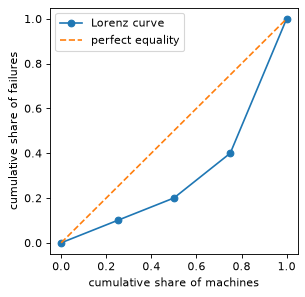

In [6]:
failures = np.sort(np.array([1, 1, 2, 6]))
share_x = np.arange(len(failures) + 1) / len(failures)
share_y = np.concatenate([[0.0], np.cumsum(failures) / failures.sum()])

# ローレンツ曲線の下の面積を台形の和で求め、ジニ係数 = 1 - 2 × 面積 とする
area = np.sum((share_x[1:] - share_x[:-1]) * (share_y[1:] + share_y[:-1]) / 2)
print(f"累積の割合（装置） {share_x}")
print(f"累積の割合（件数） {share_y}")
print(f"ジニ係数           {1 - 2 * area:.3f}")

plt.figure(figsize=(4, 4))
plt.plot(share_x, share_y, marker="o", label="Lorenz curve")
plt.plot([0, 1], [0, 1], linestyle="--", label="perfect equality")
plt.xlabel("cumulative share of machines")
plt.ylabel("cumulative share of failures")
plt.legend()
plt.show()

## 3. 分布の形と、歪度・尖度

本文の3節・7節で見た分布の形を、模擬データで確かめます。同じ個数（1000個）で、形の違う3つのデータを作ります。

- 左右対称の山形: 正規分布に従う測定値
- 右に裾が長い: 対数正規分布に従う値（例: 作業にかかる時間のように、0より小さくならず、たまに大きな値が出るもの）
- 平らな形: 一様分布に従う値

尖度は、正規分布で0になるように3を引いた値（`scipy.stats.kurtosis` の既定）を表示します。

symmetric (normal)         平均 10.021  中央値 10.020  歪度 -0.014  尖度  0.116
right-skewed (lognormal)   平均  1.181  中央値  0.978  歪度  1.557  尖度  2.991
flat (uniform)             平均  0.509  中央値  0.521  歪度 -0.060  尖度 -1.211


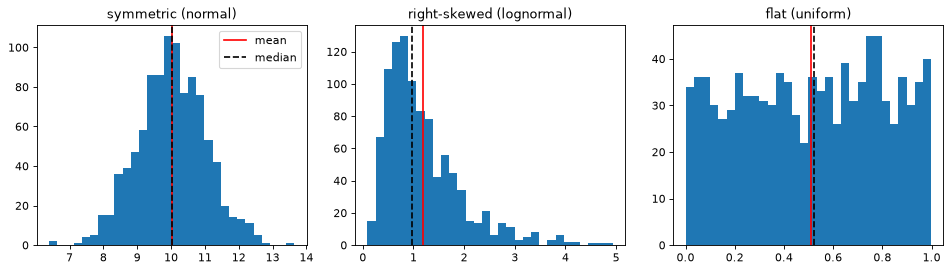

In [7]:
shapes = {
    "symmetric (normal)": rng.normal(loc=10.0, scale=1.0, size=1000),
    "right-skewed (lognormal)": rng.lognormal(mean=0.0, sigma=0.6, size=1000),
    "flat (uniform)": rng.uniform(low=0.0, high=1.0, size=1000),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, data) in zip(axes, shapes.items()):
    ax.hist(data, bins=30)
    ax.axvline(data.mean(), color="red", label="mean")
    ax.axvline(np.median(data), color="black", linestyle="--", label="median")
    ax.set_title(name)
    print(f"{name:26s} 平均 {data.mean():6.3f}  中央値 {np.median(data):6.3f}"
          f"  歪度 {stats.skew(data):6.3f}  尖度 {stats.kurtosis(data):6.3f}")
axes[0].legend()
plt.tight_layout()
plt.show()

## 4. 工学の例題: 2台のセンサのばらつきを比べる

長さが 10.000 mm と分かっている基準のブロック（ゲージブロック）を、2台のセンサ A・B でそれぞれ50回ずつ測ったとします。模擬データの条件は次のとおりです。

- センサ A: 偏り（基準からのずれ）は無く、ばらつきの標準偏差は 0.020 mm
- センサ B: 平均して +0.030 mm ずれて読む偏りがあり、ばらつきの標準偏差は 0.010 mm。さらに50回のうち2回、ノイズで +0.150 mm 大きく読んだ値が混じる

データを読む側は、この条件を知らないものとして、要約統計量とグラフから2台の特徴を読み取ります。

In [8]:
n = 50
true_length = 10.000

sensor_a = true_length + rng.normal(loc=0.0, scale=0.020, size=n)
sensor_b = true_length + 0.030 + rng.normal(loc=0.0, scale=0.010, size=n)
spikes = rng.choice(n, size=2, replace=False)
sensor_b[spikes] += 0.150

### 4-1. 要約統計量

中心（平均・中央値）、散らばり（標準偏差・四分位範囲・範囲）、形（歪度）を並べます。四分位数は本文と同じ「半分に分ける方法」で求めます。

In [9]:
def summarize(name, data):
    """1変数データの要約統計量を1行で表示する"""
    q1, q3 = quartiles_by_halves(data)
    print(f"{name}  平均 {data.mean():.4f}  中央値 {np.median(data):.4f}"
          f"  標準偏差 {data.std(ddof=1):.4f}  四分位範囲 {q3 - q1:.4f}"
          f"  最小 {data.min():.4f}  最大 {data.max():.4f}  歪度 {stats.skew(data):.2f}")


summarize("A", sensor_a)
summarize("B", sensor_b)

A  平均 10.0027  中央値 10.0015  標準偏差 0.0197  四分位範囲 0.0223  最小 9.9542  最大 10.0415  歪度 -0.15
B  平均 10.0377  中央値 10.0329  標準偏差 0.0312  四分位範囲 0.0147  最小 10.0118  最大 10.1864  歪度 4.10


### 4-2. ヒストグラムと箱ひげ図

基準の長さ 10.000 mm を破線で示します。箱ひげ図の白丸は、はずれ値の目安（四分位数から四分位範囲の1.5倍より外）に当たる点です。matplotlib の箱ひげ図は四分位数を `np.percentile` の既定の方法で求めるため、本文の方法と箱の端が少し異なることがあります。

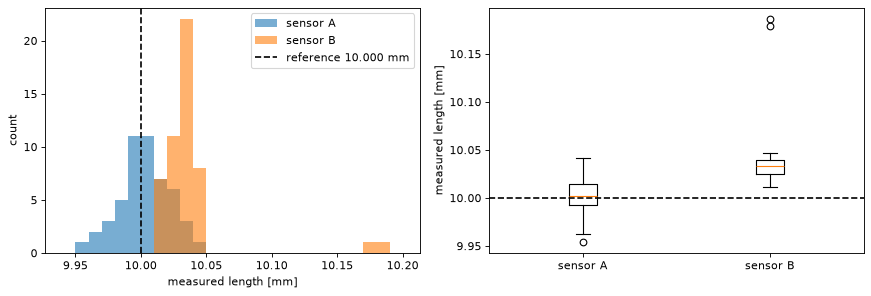

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

bins = np.linspace(9.94, 10.20, 27)
axes[0].hist(sensor_a, bins=bins, alpha=0.6, label="sensor A")
axes[0].hist(sensor_b, bins=bins, alpha=0.6, label="sensor B")
axes[0].axvline(true_length, color="black", linestyle="--", label="reference 10.000 mm")
axes[0].set_xlabel("measured length [mm]")
axes[0].set_ylabel("count")
axes[0].legend()

axes[1].boxplot([sensor_a, sensor_b], whis=1.5)
axes[1].set_xticks([1, 2], ["sensor A", "sensor B"])
axes[1].axhline(true_length, color="black", linestyle="--")
axes[1].set_ylabel("measured length [mm]")

plt.tight_layout()
plt.show()

### 4-3. はずれ値の目安に当たる点を確かめる

センサ B について、はずれ値の目安の範囲の外にある点を取り出し、それらを除いた場合の要約統計量と比べます。除いてよいかどうかは数値だけでは決まらないので、ここでは「除くと何が変わるか」を見るだけにします。

In [11]:
q1_b, q3_b = quartiles_by_halves(sensor_b)
iqr_b = q3_b - q1_b
low, high = q1_b - 1.5 * iqr_b, q3_b + 1.5 * iqr_b
is_out = (sensor_b < low) | (sensor_b > high)

print(f"はずれ値の目安の範囲 {low:.4f} 〜 {high:.4f}")
print(f"範囲の外の点        {np.round(sensor_b[is_out], 4)}")
summarize("B（全点）    ", sensor_b)
summarize("B（目安の外を除く）", sensor_b[~is_out])

はずれ値の目安の範囲 10.0030 〜 10.0616
範囲の外の点        [10.1864 10.1793]
B（全点）      平均 10.0377  中央値 10.0329  標準偏差 0.0312  四分位範囲 0.0147  最小 10.0118  最大 10.1864  歪度 4.10
B（目安の外を除く）  平均 10.0316  中央値 10.0324  標準偏差 0.0089  四分位範囲 0.0143  最小 10.0118  最大 10.0466  歪度 -0.34


## 5. まとめ

- センサ A は、平均が基準の 10.000 mm に近く、偏りは小さい一方で、ばらつき（標準偏差・四分位範囲）は B より大きい。
- センサ B は、ばらつきは小さいが、平均・中央値とも基準より約 0.03 mm 大きく、偏りがある。
- センサ B の大きく外れた2点は、平均と標準偏差を大きく動かすが、中央値と四分位範囲はほとんど動かさない。外れた値に左右されにくい指標を並べて見ると、外れ値の影響に気づきやすい。
- 「偏りが小さいこと」と「ばらつきが小さいこと」は別の性質で、1つの指標だけではセンサの良し悪しを判断できない。

読み方の詳しい説明は、本文の9節にあります。